In [1]:
import sys
sys.path.append("..")

from src.datos import cargar_obt

df = cargar_obt()
df.shape

(1017209, 57)

In [2]:
import pandas as pd
pd.set_option("display.max_rows", 100)

resumen = pd.DataFrame({
    "tipo": df.dtypes,
    "faltantes": df.isna().sum(),
    "pct_faltantes": (df.isna().mean() * 100).round(2),
})
resumen.sort_values("faltantes", ascending=False)

,tipo,faltantes,pct_faltantes
weeks_since_promo2_start,float64,577661,56.79
promo2_interval_months,str,508031,49.94
promo2_since_date,object,508031,49.94
months_since_competition_open,float64,408772,40.19
competition_open_since_date,object,324106,31.86
sales_per_customer,float64,172869,16.99
sales_mean_prev_7d,float64,4084,0.40
sales_mean_prev_28d,float64,3239,0.32
customers_mean_prev_28d,float64,3239,0.32
competition_distance_m,float64,2642,0.26


In [3]:
df_mod = df[df["is_model_eligible"]]

numericas = [
    "sales", "customers",
    "competition_distance_m", "months_since_competition_open",
    "weeks_since_promo2_start",
    "sales_mean_prev_7d", "sales_mean_prev_28d", "customers_mean_prev_28d",
    "store_coverage_ratio",
]

print(f"Filas elegibles: {len(df_mod):,} de {len(df):,}")
df_mod[numericas].describe().T.round(1)

Filas elegibles: 844,338 de 1,017,209


,count,mean,std,min,25%,50%,75%,max
sales,844338.0,6956.0,3103.8,46.0,4859.0,6369.0,8360.0,41551.0
customers,844338.0,762.8,401.2,8.0,519.0,676.0,893.0,7388.0
competition_distance_m,842152.0,5458.2,7809.6,20.0,710.0,2320.0,6890.0,75860.0
months_since_competition_open,505015.0,68.5,55.2,0.0,26.0,60.0,99.0,645.0
weeks_since_promo2_start,363805.0,131.6,77.1,0.0,67.0,127.0,191.0,313.0
sales_mean_prev_7d,842963.0,6937.5,2681.0,1158.5,5132.2,6464.0,8127.8,32368.0
sales_mean_prev_28d,843032.0,6944.3,2509.7,996.5,5261.6,6539.9,8045.7,30795.5
customers_mean_prev_28d,843032.0,762.7,371.0,139.8,541.1,678.3,872.1,3937.1
store_coverage_ratio,844338.0,1.0,0.1,0.8,1.0,1.0,1.0,1.0


In [4]:
categoricas = [
    "store_type", "assortment_label", "competition_status",
    "state_holiday_type", "is_school_holiday",
    "is_promo", "is_promo2_active", "day_of_week_iso",
]

for col in categoricas:
    tabla = df_mod.groupby(col, dropna=False)["sales"].agg(filas="count", venta_media="mean")
    tabla["venta_media"] = tabla["venta_media"].round(0)
    tabla["pct_filas"] = (tabla["filas"] / len(df_mod) * 100).round(1)
    display(tabla)

,filas,venta_media,pct_filas
store_type,,,
a,457042,6926.0,54.1
b,15560,10233.0,1.8
c,112968,6933.0,13.4
d,258768,6822.0,30.6


,filas,venta_media,pct_filas
assortment_label,,,
basic,444875,6622.0,52.7
extended,391254,7301.0,46.3
extra,8209,8643.0,1.0


,filas,venta_media,pct_filas
competition_status,,,
no_info,2186,5482.0,0.3
not_yet_open,70101,7216.0,8.3
open,505015,6931.0,59.8
unknown_since,267036,6948.0,31.6


,filas,venta_media,pct_filas
state_holiday_type,,,
christmas,71,9744.0,0.0
easter,145,9888.0,0.0
none,843428,6954.0,99.9
public,694,8487.0,0.1


,filas,venta_media,pct_filas
is_school_holiday,,,
False,680893,6897.0,80.6
True,163445,7201.0,19.4


,filas,venta_media,pct_filas
is_promo,,,
False,467463,5930.0,55.4
True,376875,8229.0,44.6


,filas,venta_media,pct_filas
is_promo2_active,,,
False,717970,7041.0,85.0
True,126368,6471.0,15.0


,filas,venta_media,pct_filas
day_of_week_iso,,,
1,137557,8216.0,16.3
2,143955,7088.0,17.0
3,141922,6729.0,16.8
4,134626,6768.0,15.9
5,138633,7073.0,16.4
6,144052,5875.0,17.1
7,3593,8225.0,0.4


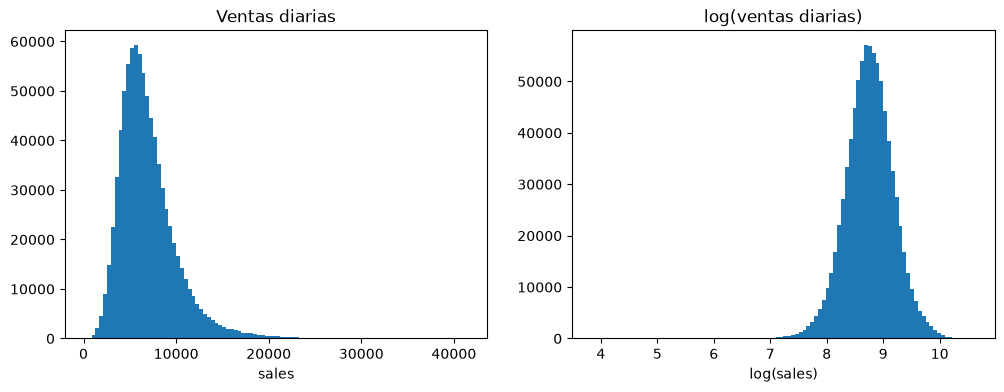

Asimetría sales: 1.59
Asimetría log(sales): -0.11
% días con ventas > 20.000: 0.49


In [5]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(df_mod["sales"], bins=100)
ax[0].set_title("Ventas diarias")
ax[0].set_xlabel("sales")

ax[1].hist(np.log(df_mod["sales"]), bins=100)
ax[1].set_title("log(ventas diarias)")
ax[1].set_xlabel("log(sales)")

plt.show()

print("Asimetría sales:", round(df_mod["sales"].skew(), 2))
print("Asimetría log(sales):", round(np.log(df_mod["sales"]).skew(), 2))
print("% días con ventas > 20.000:", round((df_mod["sales"] > 20000).mean() * 100, 2))

C:\Users\pc\AppData\Local\Temp\ipykernel_118736\4004129779.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[i].boxplot(df_mod[col].dropna(), vert=False)
C:\Users\pc\AppData\Local\Temp\ipykernel_118736\4004129779.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[i].boxplot(df_mod[col].dropna(), vert=False)


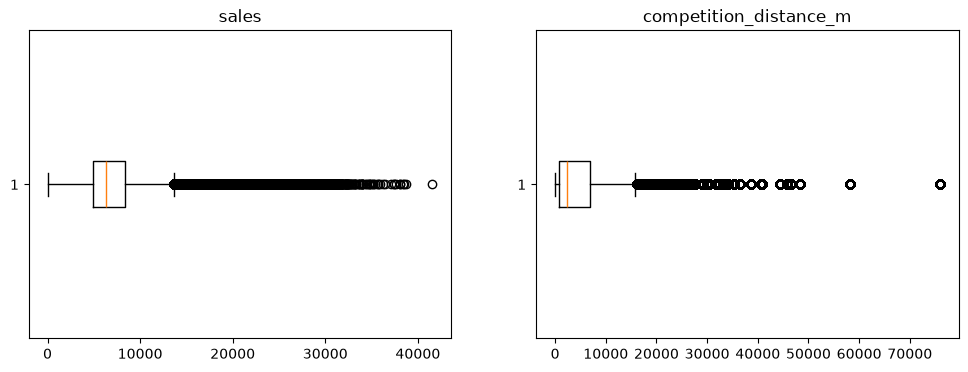

,variable,lim_inf_iqr,lim_sup_iqr,atipicos_iqr,pct_iqr,atipicos_z,pct_z
0,sales,-392.5,13611.5,30769,3.6,13443,1.6
1,competition_distance_m,-8560.0,16160.0,83040,9.9,17813,2.1


In [6]:
from scipy import stats

variables = ["sales", "competition_distance_m"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, col in enumerate(variables):
    ax[i].boxplot(df_mod[col].dropna(), vert=False)
    ax[i].set_title(col)
plt.show()

filas = []
for col in variables:
    x = df_mod[col].dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_iqr = ((x < lim_inf) | (x > lim_sup)).sum()
    n_z = (np.abs(stats.zscore(x)) >= 3).sum()
    filas.append({
        "variable": col,
        "lim_inf_iqr": lim_inf, "lim_sup_iqr": lim_sup,
        "atipicos_iqr": n_iqr, "pct_iqr": round(n_iqr / len(x) * 100, 2),
        "atipicos_z": n_z, "pct_z": round(n_z / len(x) * 100, 2),
    })

pd.DataFrame(filas).round(1)

In [7]:
q1, q3 = df_mod["sales"].quantile([0.25, 0.75])
lim_sup = q3 + 1.5 * (q3 - q1)
atipico = df_mod["sales"] > lim_sup

def perfil(d):
    return pd.Series({
        "% con promo": d["is_promo"].mean() * 100,
        "% tienda tipo b": (d["store_type"] == "b").mean() * 100,
        "% en diciembre": (d["month"] == 12).mean() * 100,
        "% en lunes": (d["day_of_week_iso"] == 1).mean() * 100,
    })

display(pd.DataFrame({
    "atipicos": perfil(df_mod[atipico]),
    "resto": perfil(df_mod[~atipico]),
}).round(1))

por_tienda = df_mod[atipico].groupby("store_id").size().sort_values(ascending=False)
print("Tiendas con al menos un día atípico:", por_tienda.size, "de", df_mod["store_id"].nunique())
print("% de días atípicos que aportan las 50 tiendas con más:",
      round(por_tienda.head(50).sum() / atipico.sum() * 100, 1))

,atipicos,resto
% con promo,72.3,43.6
% tienda tipo b,11.7,1.5
% en diciembre,17.3,5.5
% en lunes,35.6,15.6


Tiendas con al menos un día atípico: 638 de 1115
% de días atípicos que aportan las 50 tiendas con más: 62.1


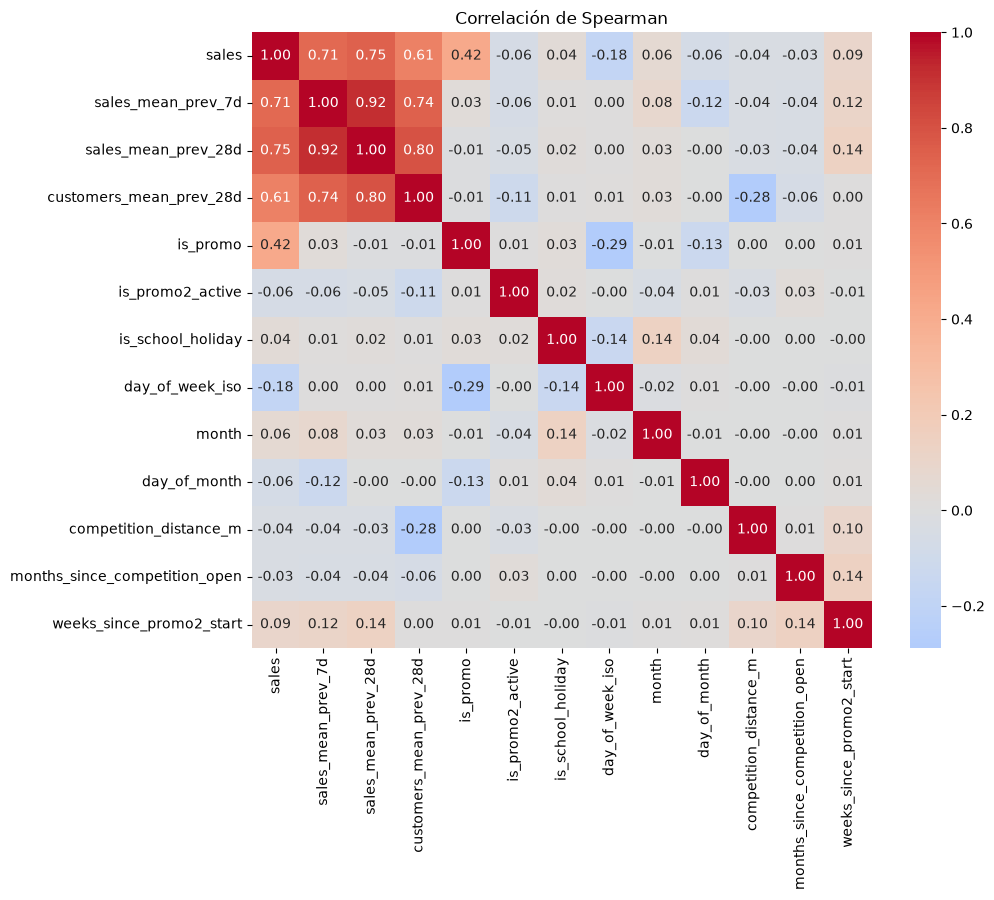

sales_mean_prev_28d              0.75
sales_mean_prev_7d               0.71
customers_mean_prev_28d          0.61
is_promo                         0.42
day_of_week_iso                 -0.18
weeks_since_promo2_start         0.09
day_of_month                    -0.06
month                            0.06
is_promo2_active                -0.06
is_school_holiday                0.04
competition_distance_m          -0.04
months_since_competition_open   -0.03
Name: sales, dtype: float64

In [8]:
import seaborn as sns

cols_corr = [
    "sales", "sales_mean_prev_7d", "sales_mean_prev_28d", "customers_mean_prev_28d",
    "is_promo", "is_promo2_active", "is_school_holiday",
    "day_of_week_iso", "month", "day_of_month",
    "competition_distance_m", "months_since_competition_open", "weeks_since_promo2_start",
]

corr = df_mod[cols_corr].astype(float).corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación de Spearman")
plt.show()

corr["sales"].drop("sales").sort_values(key=abs, ascending=False).round(2)

In [9]:
s = df[["store_id", "sales_date", "sales", "is_model_eligible"]].copy()
s["sales_date"] = pd.to_datetime(s["sales_date"])
s["sales_elig"] = s["sales"].where(s["is_model_eligible"])

tabla = s.pivot(index="sales_date", columns="store_id", values="sales_elig").asfreq("D")
media_42 = tabla.rolling(28, min_periods=1).mean().shift(42)
media_42 = media_42.stack().rename("sales_mean_lag42_28d").reset_index()

comp = df_mod[["store_id", "sales_date", "sales", "sales_mean_prev_7d", "sales_mean_prev_28d"]].copy()
comp["sales_date"] = pd.to_datetime(comp["sales_date"])
comp = comp.merge(media_42, on=["store_id", "sales_date"], how="left")

print("Faltantes en la media rezagada:", comp["sales_mean_lag42_28d"].isna().sum())
comp.drop(columns=["store_id", "sales_date"]).corr(method="spearman")["sales"].round(3)

Faltantes en la media rezagada: 46489


sales                   1.000
sales_mean_prev_7d      0.713
sales_mean_prev_28d     0.747
sales_mean_lag42_28d    0.721
Name: sales, dtype: float64

## Hallazgos del EDA

**Correlación:** se usa Spearman y no Pearson porque las ventas tienen cola larga (asimetría 1,59), hay un 3,6% de atípicos reales que se conservan y `competition_distance_m` está muy sesgada. Spearman trabaja con rangos, capta relaciones monótonas no lineales y es robusto a atípicos.

**Desbalance de clases:** no aplica; el problema es de regresión (ventas diarias).

| # | Hallazgo | Evidencia | Consecuencia en el modelo |
|---|---|---|---|
| 1 | Target con cola larga a la derecha | Asimetría de 1,59; el 0,49% de los días supera 20.000 (casi 3 veces la mediana) | Probar entrenar con log(ventas), que deja la asimetría en -0,11; evaluar siempre el WAPE en la escala original |
| 2 | Los atípicos de ventas son días reales, no errores | El 3,6% de los días supera el límite IQR (13.611). En ellos, promoción, tienda tipo b, diciembre y lunes aparecen entre 1,7 y 8 veces más que en el resto; 50 tiendas aportan el 62% | No eliminarlos; agregar una variable con el nivel de venta propio de cada tienda |
| 3 | Las medias de ventas de la OBT usan días que no existen al pronosticar a 42 días | Spearman de 0,75 con los días -28 a -1; con rezago de 42 días (días -69 a -42) baja solo a 0,72 | Reemplazarlas por la versión rezagada: misma información, sin fuga |
| 4 | Los faltantes de Promo2 y competencia son estructurales | Promo2: 544 tiendas (48,8%) no participan. Fecha de competencia: 354 tiendas (31,8%) sin registro | Imputar según su significado (indicador + valor constante), no con el promedio |